# Imports

In [34]:
source("local-functions.R")
library(ggplot2)

# Outcomes contingency tables for participants

## Study 1

716 people were given the study 1 questionnaire and 671 participated.

From those 671:
* 644 would recommend H.pylori treatement. Nobody said they wouldn't. The rest preferred not to answer, didn't know or left it blank.
* 646 would be wiling to participate in other cancer screening program
* 614 were satisfied with the care received

With regards the interactions, of the 617 that answered the three aspects:
* 33 would recommend H.pylori treatement despite not being satisfied with the care received.
* 14 were not willing to participate in other cancer screening program despite being satisfied and willing to recommend.

### Participation

I participated in the study (G01Q02): Yes, No

In [35]:
df1 = haven::read_sav("../data/Pilot1.sav")

In [36]:
df1 <- add_participation(df1)

df1 |>
      janitor::tabyl(participation, startlanguage) |>
      janitor::adorn_totals(c("row", "col"))

,participation,en,hr,lv,ro,sl,Total
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Participated,97,80,29,206,259,671
2,Didn't participate,0,4,0,0,41,45
3,Didn't answer the question,0,0,0,0,0,0
4,Total,97,84,29,206,300,716


In [37]:
df1 = df1 |> dplyr::filter(participation == 'Participated')

### Outcomes for those that participated

#### Recommendation

Would you recommend undergoing H. pylori testing and treatment? (G07Q40)
* I would strongly recommend H. pylori testing and treatment
* I would recommend H. pylori testing and treatment
* I would not recommend H. pylori testing and treatment
* I don't know
* I prefer not to answer

In [38]:
df1 = df1 |> add_recommendation(1)

In [39]:
df1 |>
      janitor::tabyl(recommendation, startlanguage) |>
      janitor::adorn_totals(c("row", "col")) |> 
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,recommendation,en,hr,lv,ro,sl,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,I would strongly recommend H. pylori testing and treatment,78,68,14,167,177,504
2,I would recommend H. pylori testing and treatment,18,8,13,28,73,140
3,I would not recommend H. pylori testing and treatment,,,,,,
4,I don’t know,1,1,,5,6,13
5,I prefer not to answer,,,1,2,,3
6,Didn't answer,,3,1,4,3,11
7,Total,97,80,29,206,259,671


In [40]:
df1 |>
      janitor::tabyl(recommendation_bin, startlanguage) |>
      janitor::adorn_totals(c("row", "col"))  |> 
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,recommendation_bin,en,hr,lv,ro,sl,Total
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,recommend,96,76,27,195,250,644
2,not recommend,,,,,,
3,NA,1,4,2,11,9,27
4,Total,97,80,29,206,259,671


#### Willingness

Would you consider participating in other cancer screening programs like TOGAS? (G07Q41)
* Most likely
* Likely
* Unsure
* Unlikely
* Very unlikely
* I prefer not to answer

In [41]:
df1 = df1 |> add_willingness(1)

In [42]:
df1 |>
      janitor::tabyl(willingness, startlanguage) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,willingness,en,hr,lv,ro,sl,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Most likely,89,68,20,155,222,554
2,Likely,8,12,7,40,25,92
3,Unsure/Unlikely,,,2,7,10,19
4,I prefer not to answer,,,,,,
5,Didn't answer,,,,4,2,6
6,Total,97,80,29,206,259,671


#### Satisfaction

Are you overall satisfied with the care you received? (G07Q39)
* Very satisfied
* Satisfied
* Neither satisfied nor disappointed
* Disappointed
* Very disappointed
* I don’t know
* I prefer not to answer

In [43]:
df1 = df1 |> add_satisfaction(1)

In [44]:
df1 |>janitor::tabyl(satisfaction, startlanguage) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,satisfaction,en,hr,lv,ro,sl,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Very satisfied,86,57,4,106,170,423
2,Satisfied,10,16,20,74,71,191
3,Not satisfied,1,2,4,20,14,41
4,I don't know/I prefer not to answer,,,1,,3,4
5,Didn't answer,,5,,6,1,12
6,Total,97,80,29,206,259,671


### Contingency tables

#### Recommendation vs Satisfaction

In [45]:
df1 |> janitor::tabyl(recommendation, satisfaction ) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,recommendation,Very satisfied,Satisfied,Not satisfied,I don't know/I prefer not to answer,Didn't answer,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,I would strongly recommend H. pylori testing and treatment,365,113,18,2,6,504
2,I would recommend H. pylori testing and treatment,52,69,18,1,,140
3,I would not recommend H. pylori testing and treatment,,,,,,
4,I don’t know,4,6,2,1,,13
5,I prefer not to answer,,1,2,,,3
6,Didn't answer,2,2,1,,6,11
7,Total,423,191,41,4,12,671


#### Recommendation vs Willingness

In [46]:
df1 |> janitor::tabyl(recommendation, willingness ) |>
      janitor::adorn_totals(c("row", "col"))  |>
      dplyr::mutate(
        across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x)))
      )

,recommendation,Most likely,Likely,Unsure/Unlikely,I prefer not to answer,Didn't answer,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,I would strongly recommend H. pylori testing and treatment,453,43,7,,1,504
2,I would recommend H. pylori testing and treatment,89,40,10,,1,140
3,I would not recommend H. pylori testing and treatment,,,,,,
4,I don’t know,8,4,1,,,13
5,I prefer not to answer,,2,1,,,3
6,Didn't answer,4,3,,,4,11
7,Total,554,92,19,,6,671


#### Satisfaction vs Willingness

In [47]:
df1 |> janitor::tabyl(satisfaction, willingness ) |>
      janitor::adorn_totals(c("row", "col"))

,satisfaction,Most likely,Likely,Unsure/Unlikely,I prefer not to answer,Didn't answer,Total
,<ord>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Very satisfied,391,28,3,0,1,423
2,Satisfied,128,51,11,0,1,191
3,Not satisfied,26,10,5,0,0,41
4,I don't know/I prefer not to answer,2,2,0,0,0,4
5,Didn't answer,7,1,0,0,4,12
6,Total,554,92,19,0,6,671


#### Recommendation, satisfaction and willingness (simple view)

In [48]:
tabyl_obj = df1 |>  dplyr::filter(recommendation_bin %in% c("recommend", "not recommend")) |>
        dplyr::filter(satisfaction_bin %in% c("satisfied", "not satisfied")) |>
        dplyr::filter(willingness_bin %in% c("willing", "not willing")) |>
    janitor::tabyl(recommendation_bin, satisfaction_bin, willingness_bin) 

tabyl_obj |>
      janitor::adorn_totals(c("row", "col")) |>
      purrr::map(~ .x |> 
        dplyr::mutate(across(
          where(is.numeric),
          ~ ifelse(.x == 0, "", as.character(.x))
        )))

,recommendation_bin,satisfied,not satisfied,Total
,<fct>,<chr>,<chr>,<chr>
1,recommend,584,33,617
2,not recommend,,,
3,Total,584,33,617
,recommendation_bin,satisfied,not satisfied,Total
,<fct>,<chr>,<chr>,<chr>
1,recommend,14,3,17
2,not recommend,,,
3,Total,14,3,17


In [49]:
attributes(tabyl_obj |> dplyr::bind_rows(.id = "willingness_bin"))

recommendation_bin,satisfied,not satisfied
<fct>,<dbl>,<dbl>
recommend,584,33
not recommend,0,0


In [50]:
gt_table = tabyl_obj |> dplyr::bind_rows(.id = "willingness_bin") |>
  gt::gt(
    rowname_col = "recommendation_bin",
    groupname_col = "satisfaction_bin"
  ) |> 
  gt::tab_spanner(
    columns = 3:4,
    label = "Satisfied with care?"
  ) |>
  gt::tab_style(
    style = gt::cell_text(weight = "bold"),
    locations = gt::cells_row_groups()
  )
IRdisplay::display_html(gt::as_raw_html(gt_table))

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" scope="col" id="a::stub" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left"> 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="2" colspan="1" scope="col" id="willingness_bin" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">willingness_bin 
 
 Satisfied with care? 
 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" scope="col" id="satisfied" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" bgcolor="#FFFFFF" valign="bottom" align="right">satisfied 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" scope="col" id="not-satisfied" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" bgcolor="#FFFFFF" valign="bottom" align="right">not satisfied 
 
 
 
 <th id="stub_1_1" scope="row" class="gt_row gt_center gt_stub" style="border-style: none; padding-top: 8px; padding-bottom: 8px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: initial; text-transform: inherit; border-right-style: solid; border-right-width: 2px; border-right-color: #D3D3D3; padding-left: 5px; padding-right: 5px; text-align: center;" va

#### Recommendation, satisfaction and willingness

In [51]:
df1 |> janitor::tabyl(recommendation, satisfaction, willingness) |>
      janitor::adorn_totals(c("row", "col")) |>
      purrr::map(~ .x |> 
        dplyr::mutate(across(
          where(is.numeric),
          ~ ifelse(.x == 0, "", as.character(.x))
        )))

,recommendation,Very satisfied,Satisfied,Not satisfied,I don't know/I prefer not to answer,Didn't answer,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,I would strongly recommend H. pylori testing and treatment,2,4,1,,,7
2,I would recommend H. pylori testing and treatment,1,7,2,,,10
3,I would not recommend H. pylori testing and treatment,,,,,,
4,I don’t know,,,1,,,1
5,I prefer not to answer,,,1,,,1
6,Didn't answer,,,,,,
7,Total,3,11,5,,,19
,recommendation,Very satisfied,Satisfied,Not satisfied,I don't know/I prefer not to answer,Didn't answer,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


## Study 2

1254 people were given the study 2 questionnaire and 1079 participated.

From those 1079:
* 604 would recommend an endoscopy and colonoscopy in  the same session. 2 wouldn't recommend. The rest preferred not to answer, didn't know or left it blank.
* 945 would be wiling to participate in other cancer screening program, 62 were unsure, 6 wouldn't and the rest didn't answer
* 866 were satisfied with the care received, and only 1 was disappointed.

With regards the interactions, of the 406 that answered the three aspects:
* 28 were not willing to participate in other cancer screening program despite being satisfied and willing to recommend.

### Participation

In [52]:
df2 = haven::read_sav("../data/Pilot2.sav")

In [53]:
df2 <- add_participation(df2)
df2 |>
      janitor::tabyl(participation, startlanguage) |>
      janitor::adorn_totals(c("row", "col"))

,participation,de,en,es,fr,lt,lv,nl,pt,Total
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Participated,60,48,139,130,242,183,121,156,1079
2,Didn't participate,1,5,22,0,14,60,29,5,136
3,Didn't answer the question,9,11,0,2,0,11,5,1,39
4,Total,70,64,161,132,256,254,155,162,1254


In [54]:
df2 = df2 |> dplyr::filter(participation == 'Participated')

### Outcomes for those that participated

#### Recommendation

Question: Are you overall satisfied with the care you received and would recommend undergoing endoscopy and colonoscopy in the same session?
* I wouldn’t recommend an endoscopy and a colonoscopy in the same session to others (column G05Q22_SQ006)
* I would strongly recommend an endoscopy and a colonoscopy in the same session to others (G05Q22_SQ002)

In [81]:
df2 |> dplyr::filter(G05Q22_SQ002 == 'Y' & G05Q22_SQ006 == 'Y')

id,submitdate,lastpage,startlanguage,seed,startdate,datestamp,G01Q01,G01Q02,G00Q26,⋯,If_ther_is_a_need_for_additional,participation,recommendation,recommendation_bin,willingness,willingness_bin,satisfaction,satisfaction_bin,repeat_procedure,recommend_procedure
<dbl>,<dttm>,<dbl>,<chr>,<dbl>,<dttm>,<dttm>,<chr+lbl>,<chr+lbl>,<chr+lbl>,⋯,<dbl+lbl>,<fct>,<chr>,<chr>,<ord>,<chr>,<ord>,<chr>,<fct>,<fct>
67,2025-07-24 14:03:32,6,fr,216412101,2025-07-24 14:00:03,2025-07-24 14:03:32,AO01,AO01,AO01,⋯,1,Participated,not recommend,not recommend,I most likely would,willing,very satisfied,satisfied,would repeat,NA


In [55]:
df2 = df2 |> add_recommendation(2)

In [56]:
df2 |>
      janitor::tabyl(recommendation, startlanguage) |>
      janitor::adorn_totals(c("row", "col")) |> 
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,recommendation,de,en,es,fr,lt,lv,nl,pt,Total
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Didn't answer,19,22,65,53,112,90,61,51,473
2,not recommend,,1,,1,,,,,2
3,recommend,41,25,74,76,130,93,60,105,604
4,Total,60,48,139,130,242,183,121,156,1079


#### Willingness

Would you consider participating in cancer screening programmes like TOGAS? (G05Q23)
* I certainly would
* I most likely would
* I likely would
* I’m unsure
* It is unlikely that I would
* It is very unlikely that I would
* I prefer not to answer

In [57]:
df2 = df2 |> add_willingness(2)

In [58]:
df2 |> janitor::tabyl(willingness, startlanguage) |>
      janitor::adorn_totals(c("row", "col")) |> 
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,willingness,de,en,es,fr,lt,lv,nl,pt,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,I certainly would,26,39,81,35,166,69,7,63,486
2,I most likely would,15,3,45,26,50,71,44,34,288
3,I likely would,17,1,13,31,13,21,49,26,171
4,I’m unsure,,4,,10,9,17,12,10,62
5,It is unlikely that I would,,,,,1,2,1,,4
6,It is very unlikely that I would,,,,,2,1,,,3
7,I prefer not to answer,1,,,10,1,,6,10,28
8,NA,1,1,,18,,2,2,13,37
9,Total,60,48,139,130,242,183,121,156,1079


#### Satisfaction

Question: Are you overall satisfied with the care you received and would recommend undergoing endoscopy and colonoscopy in the same session?
* I am very satisfied with the care I received (G05Q22_SQ001)
* I am satisfied with the care I received (G05Q22_SQ004)
* I am very disappointed with the care I received (G05Q22_SQ005)

##### Inconsistencies

Count of people selecting, 0, 1, 2, or 3 options. Some people selected two options related to the same 'satisfaction' dimension, seven of them selected two inconsistent options.

In [59]:
selection_counts <- df2 |>
  dplyr::mutate(
    n_selected = rowSums(
      dplyr::across(
        c(G05Q22_SQ001, G05Q22_SQ004, G05Q22_SQ005),
        ~ .x == "Y"
      ),
      na.rm = TRUE
    )
  ) |>
  dplyr::count(n_selected, name = "count") |>
  dplyr::arrange(n_selected)

selection_counts

n_selected,count
<dbl>,<int>
0,212
1,788
2,79


In [60]:
df2 |> dplyr::filter(G05Q22_SQ001=='Y' & G05Q22_SQ005=='Y') 

id,submitdate,lastpage,startlanguage,seed,startdate,datestamp,G01Q01,G01Q02,G00Q26,⋯,discomfort_recoded,After_procedures_info,would_you_consider_recoded,Education_cat,If_ther_is_a_need_for_additional,participation,recommendation,recommendation_bin,willingness,willingness_bin
<dbl>,<dttm>,<dbl>,<chr>,<dbl>,<dttm>,<dttm>,<chr+lbl>,<chr+lbl>,<chr+lbl>,⋯,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<fct>,<chr>,<chr>,<ord>,<chr>
8,2024-07-23 14:58:25,6,nl,1652754412,2024-07-23 14:55:07,2024-07-23 14:58:25,AO01,AO01,AO01,⋯,1,1,1,2,1,Participated,recommend,recommend,I most likely would,willing
27,2024-10-07 12:52:53,6,nl,1114479786,2024-10-07 12:50:35,2024-10-07 12:52:53,AO01,AO01,AO01,⋯,1,1,1,3,1,Participated,recommend,recommend,I most likely would,willing
44,2024-12-09 12:45:31,6,nl,1867189933,2024-12-09 12:43:20,2024-12-09 12:45:31,AO01,AO01,AO01,⋯,1,1,1,3,1,Participated,recommend,recommend,I most likely would,willing
68,2025-02-18 14:24:19,6,nl,566812841,2025-02-18 14:20:46,2025-02-18 14:24:19,AO01,AO01,AO01,⋯,2,1,1,3,1,Participated,recommend,recommend,I likely would,willing
95,2025-06-04 10:31:59,6,nl,43942755,2025-06-04 10:29:32,2025-06-04 10:31:59,AO01,AO01,AO01,⋯,2,1,1,1,1,Participated,recommend,recommend,I most likely would,willing
105,2025-07-17 16:18:54,6,nl,802912672,2025-07-17 16:15:15,2025-07-17 16:18:54,AO01,AO01,AO01,⋯,1,1,1,1,2,Participated,recommend,recommend,I likely would,willing
114,2025-09-18 11:11:26,6,nl,288673225,2025-09-18 11:08:02,2025-09-18 11:11:26,AO01,AO01,AO01,⋯,1,1,1,2,1,Participated,recommend,recommend,I certainly would,willing


##### Satisfaction column

In [61]:
df2 = df2 |> add_satisfaction(2)

In [62]:
df2 |>janitor::tabyl(satisfaction, startlanguage) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,satisfaction,de,en,es,fr,lt,lv,nl,pt,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,very satisfied,45,41,104,81,177,155,69,107,779
2,satisfied,4,2,22,18,22,7,4,8,87
3,disappointed,,,,,,,1,,1
4,NA,11,5,13,31,43,21,47,41,212
5,Total,60,48,139,130,242,183,121,156,1079


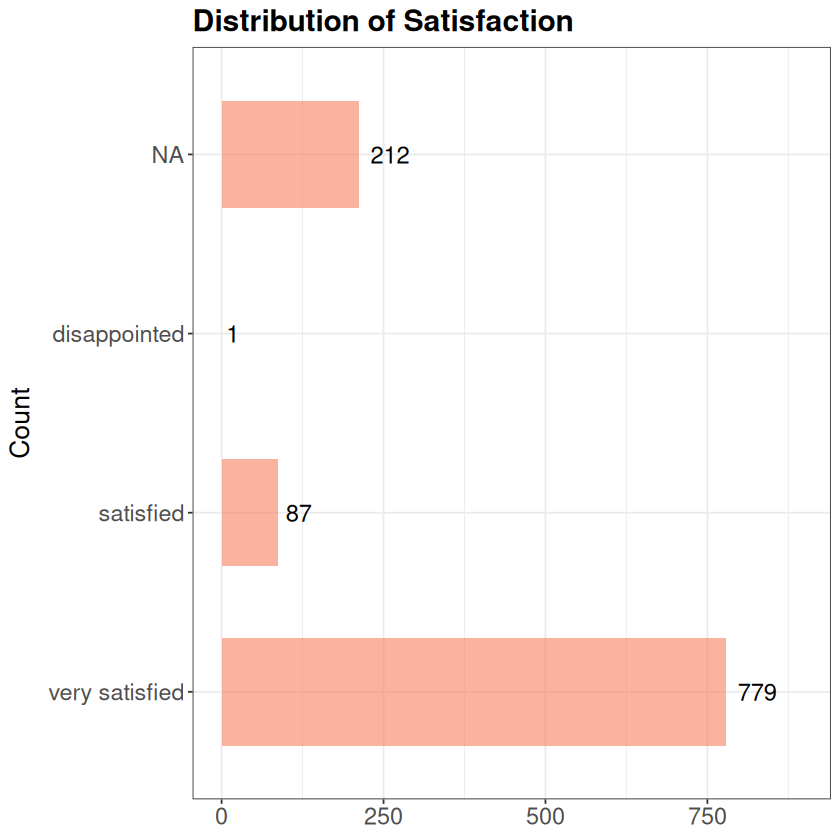

In [63]:
df2 |> ggplot(aes(y = satisfaction)) +
  geom_bar(fill="#f68060", alpha=.6, width=.6) +
  geom_text(
    stat = "count",
    aes(label = after_stat(count)),
    hjust = -0.3,
    size = 5
  ) +
  labs(
    y = "Count",
    x = NULL,
    title = "Distribution of Satisfaction"
  ) +
  theme_bw() +
  theme(
    axis.text = element_text(size = 14),
    axis.title = element_text(size = 16),
    plot.title = element_text(size = 18, face = "bold")      
  ) +
  expand_limits(x = max(table(df2$satisfaction)) * 1.15)

### Contingency tables

#### Recommendation vs Satisfaction

In [64]:
df2 |> janitor::tabyl(recommendation, satisfaction ) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,recommendation,very satisfied,satisfied,disappointed,NA_,Total
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Didn't answer,379,46,1,47,473
2,not recommend,1,,,1,2
3,recommend,399,41,,164,604
4,Total,779,87,1,212,1079


#### Recommendation vs Willingness

In [65]:
df2 |> janitor::tabyl(recommendation, willingness ) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,recommendation,I certainly would,I most likely would,I likely would,I’m unsure,It is unlikely that I would,It is very unlikely that I would,I prefer not to answer,NA_,Total
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Didn't answer,202,120,78,35,3,2,9,24,473
2,not recommend,1,1,,,,,,,2
3,recommend,283,167,93,27,1,1,19,13,604
4,Total,486,288,171,62,4,3,28,37,1079


#### Satisfaction vs Willingness

In [66]:
df2 |> janitor::tabyl(satisfaction, willingness ) |>
      janitor::adorn_totals(c("row", "col")) |>
      dplyr::mutate(across(where(is.numeric), ~ ifelse(.x == 0, "", as.character(.x))))

,satisfaction,I certainly would,I most likely would,I likely would,I’m unsure,It is unlikely that I would,It is very unlikely that I would,I prefer not to answer,NA_,Total
,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,very satisfied,410,205,92,36,2,2,15,17,779
2,satisfied,21,26,30,7,,,1,2,87
3,disappointed,,,,1,,,,,1
4,NA,55,57,49,18,2,1,12,18,212
5,Total,486,288,171,62,4,3,28,37,1079


#### Recommendation, satisfaction and willingness (binary)

In [73]:
tabyl_obj = df2 |> dplyr::filter(recommendation_bin %in% c("recommend", "not recommend")) |>
        dplyr::filter(satisfaction_bin %in% c("satisfied", "not satisfied")) |>
        dplyr::filter(willingness_bin %in% c("willing", "not willing")) |>
    janitor::tabyl(recommendation_bin, satisfaction_bin, willingness_bin) 

tabyl_obj |>
      janitor::adorn_totals(c("row", "col")) |>
      purrr::map(~ .x |> 
        dplyr::mutate(across(
          where(is.numeric),
          ~ ifelse(.x == 0, "", as.character(.x))
        )))

,recommendation_bin,satisfied,Total
,<chr>,<chr>,<chr>
1,not recommend,,
2,recommend,28,28
3,Total,28,28
,recommendation_bin,satisfied,Total
,<chr>,<chr>,<chr>
1,not recommend,1,1
2,recommend,405,405
3,Total,406,406


In [75]:
attributes(tabyl_obj |> dplyr::bind_rows(.id = "willingness_bin"))

recommendation_bin,satisfied
<chr>,<dbl>
not recommend,0
recommend,28


In [79]:
gt_table = tabyl_obj |> dplyr::bind_rows(.id = "willingness_bin") |>
  gt::gt(
    rowname_col = "recommendation_bin",
    groupname_col = "satisfaction_bin"
  ) |> 
  gt::tab_spanner(
    columns = 1:4,
    label = "Satisfied with care?"
  ) |>
  gt::tab_style(
    style = gt::cell_text(weight = "bold"),
    locations = gt::cells_row_groups()
  )
IRdisplay::display_html(gt::as_raw_html(gt_table))

ERROR: [1m[33mError[39m in `gt::tab_spanner()`:[22m
[33m![39m Can't select columns past the end.
[1m[22m[36mℹ[39m Location 4 doesn't exist.
[36mℹ[39m There are only 3 columns.


#### Recommendation, satisfaction and willingness

In [68]:
df2 |> janitor::tabyl(recommendation, satisfaction, willingness) |>
      janitor::adorn_totals(c("row", "col")) |>
      purrr::map(~ .x |> 
        dplyr::mutate(across(
          where(is.numeric),
          ~ ifelse(.x == 0, "", as.character(.x))
        )))

,recommendation,very satisfied,satisfied,disappointed,NA_,Total
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Didn't answer,193,4,,5,202
2,not recommend,,,,1,1
3,recommend,217,17,,49,283
4,Total,410,21,,55,486
,recommendation,very satisfied,satisfied,disappointed,NA_,Total
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Didn't answer,97,16,,7,120
2,not recommend,1,,,,1
3,recommend,107,10,,50,167


## Other things

#### Repeat procedure

The options about repeating or recommending the procedure don't show inconsistencies, that is participants didn't choose two options that were incompatible.

Question: Are you overall satisfied with the care you received and would recommend undergoing endoscopy and colonoscopy in the same session?

* I would be willing to repeat both procedures if necessary (G05Q22_SQ003)
* I wouldn't repeat both procedures in the same session ( G05Q22_SQ007)

In [69]:
selection_counts <- df2 |>
  dplyr::mutate(
    n_selected = rowSums(
      dplyr::across(
        c(G05Q22_SQ003, G05Q22_SQ007),
        ~ .x == "Y"
      ),
      na.rm = TRUE
    )
  ) |>
  dplyr::count(n_selected, name = "count") |>
  dplyr::arrange(n_selected)

selection_counts

n_selected,count
<dbl>,<int>
0,804
1,274
2,1


In [70]:
df2 <- df2 |>
  dplyr::mutate(
    repeat_procedure = dplyr::case_when(
      G05Q22_SQ003 == "Y" ~ 1,
      G05Q22_SQ007 == "Y" ~ 2,
      TRUE ~ NA_real_
    ),
    repeat_procedure = factor(
      repeat_procedure,
      levels = c(1, 2),
      labels = c("would repeat", "wouldn't repeat")
    ),
  )

#### Recommend procedure

Question: Are you overall satisfied with the care you received and would recommend undergoing endoscopy and colonoscopy in the same session?

* I would strongly recommend an endoscopy and a colonoscopy in the same session to others ( G05Q22_SQ002)
* I wouldn't recommend an endoscopy and a colonoscopy in the same session to others ( G05Q22_SQ006)

In [71]:
selection_counts <- df2 |>
  dplyr::mutate(
    n_selected = rowSums(
      dplyr::across(
        c(G05Q22_SQ002, G05Q22_SQ006),
        ~ .x == "Y"
      ),
      na.rm = TRUE
    )
  ) |>
  dplyr::count(n_selected, name = "count") |>
  dplyr::arrange(n_selected)

selection_counts

n_selected,count
<dbl>,<int>
0,473
1,605
2,1


In [72]:
df2 <- df2 |>
  dplyr::mutate(
    recommend_procedure = dplyr::case_when(
      G05Q22_SQ002 == "Y" ~ 1,
      G05Q22_SQ006 == "Y" ~ 2,
      TRUE ~ NA_real_
    ),
    recommend_procedure = factor(
      repeat_procedure,
      levels = c(1, 2),
      labels = c("would recommend", "wouldn't recommend")
    ),
  )